Import thư viện

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [2]:
import os
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import multivariate_normal

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Cố định seed để kết quả tái lập được
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)

Using device: cpu


Chuẩn bị dữ liệu

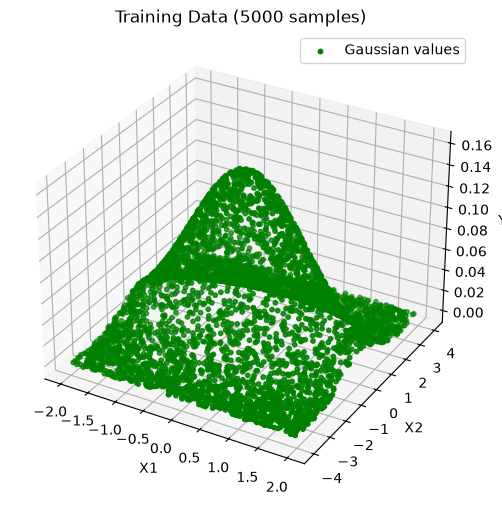

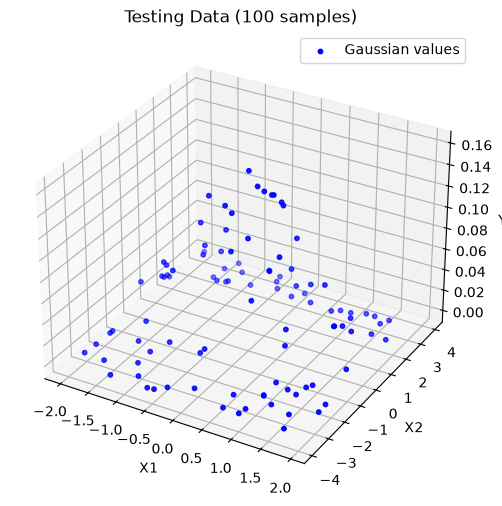

In [3]:
def generate_data(n_samples, r1=(-2, 2), r2=(-4, 4), mean=[0.0, 0.0], cov=[[1.0, 0.0], [0.0, 1.0]], save_path=None):
    x1 = np.random.uniform(r1[0], r1[1], size=(n_samples, 1))
    x2 = np.random.uniform(r2[0], r2[1], size=(n_samples, 1))
    x = np.hstack([x1, x2])
    y = multivariate_normal.pdf(x, mean=mean, cov=cov)

    df = pd.DataFrame({"x1": x[:, 0], "x2": x[:, 1], "y": y})
    if save_path:
        df.to_csv(save_path, index=False)
    return x, y

def load_data(csv_path):
    df = pd.read_csv(csv_path)
    x = df[["x1", "x2"]].values.astype(np.float32)
    y = df["y"].values.astype(np.float32)
    return x, y

def plot_3d_dataset(x, y, title="2D Gaussian", color="green", save_path=None):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(x[:, 0], x[:, 1], y, c=color, s=10, label="Gaussian values")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_zlabel("Y")
    ax.set_title(title)
    ax.legend()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

# Sinh và lưu dữ liệu (5000 train, 100 test)
generate_data(5000, save_path="data/training-data.csv")
generate_data(100, save_path="data/testing-data.csv")

# Đọc lại và vẽ thử
x_train, y_train = load_data("data/training-data.csv")
x_test, y_test = load_data("data/testing-data.csv")

plot_3d_dataset(x_train, y_train, title="Training Data (5000 samples)", color="green", save_path="results/train_data.png")
plot_3d_dataset(x_test, y_test, title="Testing Data (100 samples)", color="blue", save_path="results/test_data.png")

Xây dựng mô hình MLP

In [4]:
class GeneralMLP(nn.Module):
    def __init__(self, n_input=2, n_output=1, hidden_nodes=[128, 128]):
        super().__init__()
        layers = []
        in_dim = n_input
        for h in hidden_nodes:
            layers.append(nn.Linear(in_dim, h))
            layers.append(nn.Sigmoid())
            in_dim = h
        layers.append(nn.Linear(in_dim, n_output))
        layers.append(nn.Sigmoid())
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def train_and_evaluate(x_tr, y_tr, x_te, y_te, hidden_nodes=[128, 128],
                       epochs=100, batch_size=32, lr=0.01, verbose=False):
    # Chuẩn bị DataLoader
    tr_ds = TensorDataset(torch.tensor(x_tr, dtype=torch.float32),
                          torch.tensor(y_tr, dtype=torch.float32).unsqueeze(1))
    tr_loader = DataLoader(tr_ds, batch_size=batch_size, shuffle=True)

    x_tr_t = torch.tensor(x_tr, dtype=torch.float32, device=device)
    y_tr_t = torch.tensor(y_tr, dtype=torch.float32, device=device).unsqueeze(1)
    x_te_t = torch.tensor(x_te, dtype=torch.float32, device=device)
    y_te_t = torch.tensor(y_te, dtype=torch.float32, device=device).unsqueeze(1)

    model = GeneralMLP(n_input=2, n_output=1, hidden_nodes=hidden_nodes).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)

    train_losses, test_losses = [], []

    for epoch in range(epochs):
        model.train()
        for xb, yb in tr_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            tr_loss = criterion(model(x_tr_t), y_tr_t).item()
            te_loss = criterion(model(x_te_t), y_te_t).item()
            train_losses.append(tr_loss)
            test_losses.append(te_loss)

        if verbose and (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch+1}/{epochs} - Train Loss: {tr_loss:.6f} - Test Loss: {te_loss:.6f}")

    model.eval()
    with torch.no_grad():
        y_pred = model(x_te_t).cpu().numpy().flatten()

    return model, train_losses, test_losses, y_pred

def plot_curve(x_vals, train_vals, test_vals, xlabel, ylabel, title, save_path=None):
    plt.figure(figsize=(8, 5))
    plt.plot(x_vals, train_vals, label="Training")
    plt.plot(x_vals, test_vals, label="Testing")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.grid(True)
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

Chạy mô hình cơ bản

Epoch 20/200 - Train Loss: 0.001641 - Test Loss: 0.001982
Epoch 40/200 - Train Loss: 0.001639 - Test Loss: 0.001980
Epoch 60/200 - Train Loss: 0.001638 - Test Loss: 0.001979
Epoch 80/200 - Train Loss: 0.001637 - Test Loss: 0.001978
Epoch 100/200 - Train Loss: 0.001636 - Test Loss: 0.001977
Epoch 120/200 - Train Loss: 0.001635 - Test Loss: 0.001976
Epoch 140/200 - Train Loss: 0.001634 - Test Loss: 0.001975
Epoch 160/200 - Train Loss: 0.001633 - Test Loss: 0.001974
Epoch 180/200 - Train Loss: 0.001632 - Test Loss: 0.001972
Epoch 200/200 - Train Loss: 0.001631 - Test Loss: 0.001971


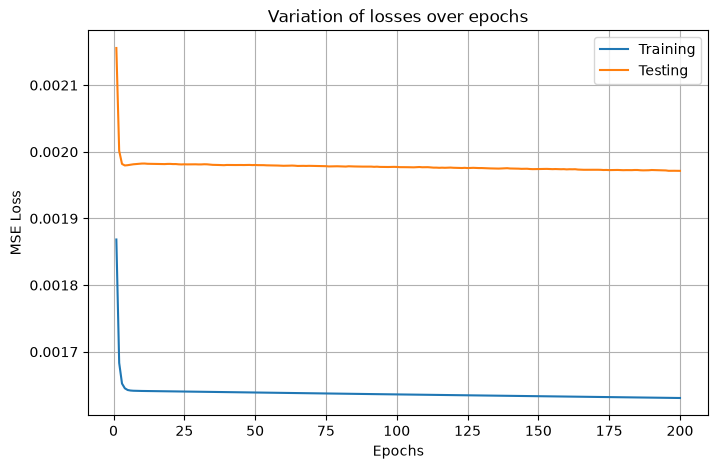

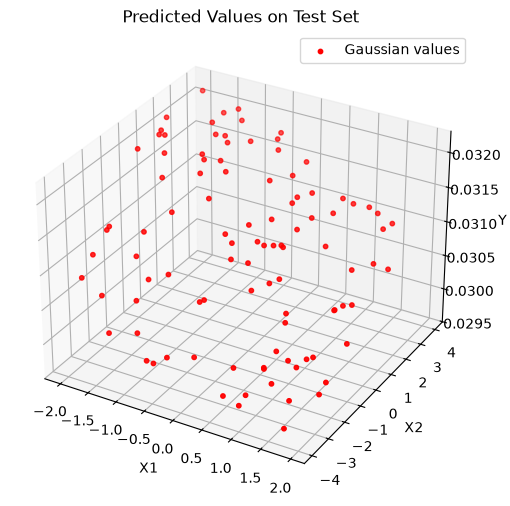

In [5]:
model, tr_losses, te_losses, y_pred = train_and_evaluate(
    x_train, y_train, x_test, y_test,
    hidden_nodes=[128, 128], epochs=200, batch_size=32, lr=0.05, verbose=True
)

plot_curve(range(1, 201), tr_losses, te_losses,
           xlabel="Epochs", ylabel="MSE Loss",
           title="Variation of losses over epochs",
           save_path="results/gauss_train.png")

plot_3d_dataset(x_test, y_pred, title="Predicted Values on Test Set", color="red", save_path="results/gauss_predict.png")

Chạy 3 thực nghiệm

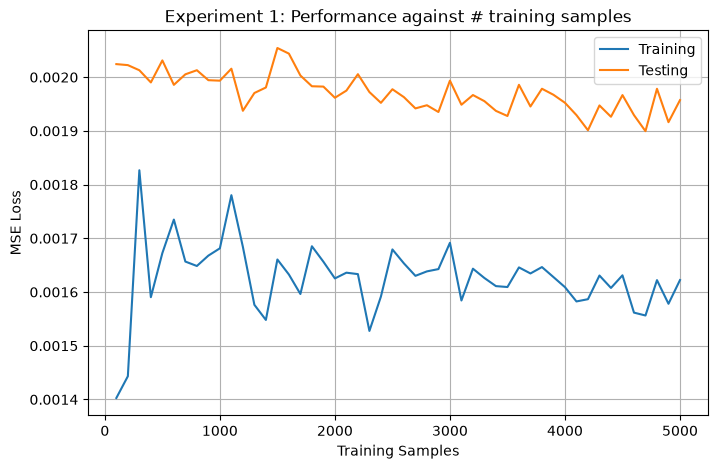

In [6]:
sizes = list(range(100, 5001, 100))
exp1_tr, exp1_te = [], []

for size in sizes:
    idx = np.random.choice(len(x_train), size=size, replace=False)
    _, tr_l, te_l, _ = train_and_evaluate(
        x_train[idx], y_train[idx], x_test, y_test,
        hidden_nodes=[128], epochs=100, batch_size=32, lr=0.05
    )
    exp1_tr.append(tr_l[-1])
    exp1_te.append(te_l[-1])

pd.DataFrame({"size": sizes, "train_loss": exp1_tr, "test_loss": exp1_te}).to_csv("results/experiment1.csv", index=False)
plot_curve(sizes, exp1_tr, exp1_te, "Training Samples", "MSE Loss",
           "Experiment 1: Performance against # training samples", "results/experiment1.png")

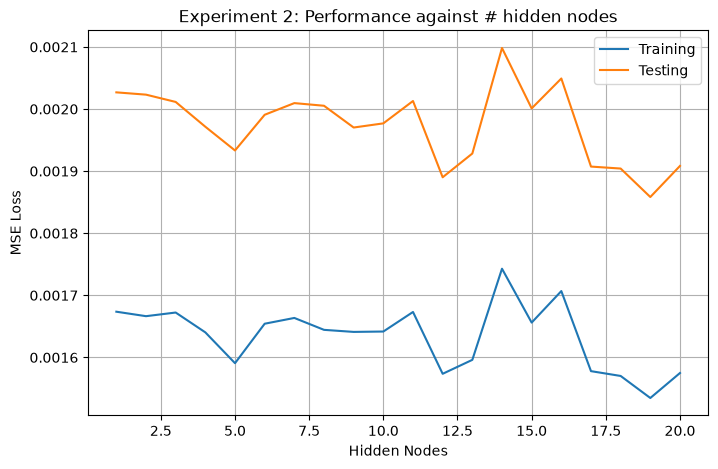

In [7]:
nodes_list = list(range(1, 21))
exp2_tr, exp2_te = [], []

for n_nodes in nodes_list:
    _, tr_l, te_l, _ = train_and_evaluate(
        x_train, y_train, x_test, y_test,
        hidden_nodes=[n_nodes], epochs=100, batch_size=32, lr=0.05
    )
    exp2_tr.append(tr_l[-1])
    exp2_te.append(te_l[-1])

pd.DataFrame({"hidden_nodes": nodes_list, "train_loss": exp2_tr, "test_loss": exp2_te}).to_csv("results/experiment2.csv", index=False)
plot_curve(nodes_list, exp2_tr, exp2_te, "Hidden Nodes", "MSE Loss",
           "Experiment 2: Performance against # hidden nodes", "results/experiment2.png")

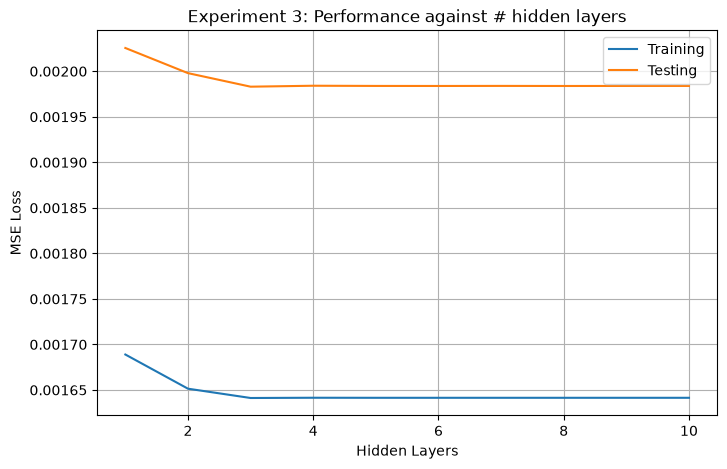

In [8]:
layers_list = list(range(1, 11))
exp3_tr, exp3_te = [], []

for n_layers in layers_list:
    _, tr_l, te_l, _ = train_and_evaluate(
        x_train, y_train, x_test, y_test,
        hidden_nodes=[10] * n_layers, epochs=100, batch_size=32, lr=0.05
    )
    exp3_tr.append(tr_l[-1])
    exp3_te.append(te_l[-1])

pd.DataFrame({"hidden_layers": layers_list, "train_loss": exp3_tr, "test_loss": exp3_te}).to_csv("results/experiment3.csv", index=False)
plot_curve(layers_list, exp3_tr, exp3_te, "Hidden Layers", "MSE Loss",
           "Experiment 3: Performance against # hidden layers", "results/experiment3.png")